<a href="https://colab.research.google.com/github/NetanelFarhi/mura-wrist-ml-pipeline/blob/ARTEM/notebooks/01_MURA_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MURA Wrist — Data Preparation

Prepares the wrist subset of **MURA v1.1** for the project *Agentic AI-Assisted Detection of
Musculoskeletal Abnormalities in Emergency X-rays*:

1. verifies the source data (file index ↔ ZIP archive),
2. parses patient, study and label from the image paths,
3. creates a patient-level internal train / validation split,
4. exports the manifests to `DATA/WRIST_SPLITS`.

**Run order:** top to bottom. Files that already exist in the shared folder are never
overwritten silently: they are re-computed and compared (`ALLOW_OVERWRITE = False`).

**Data folder:** found automatically - `MyDrive/DATA` (shortcut) or `MyDrive/Final Project DS23/.../DATA`; both are the same shared folder.

## Setup

### Step 1 — Mount Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Step 2 — Project configuration (single source of truth for all paths)

In [2]:
from pathlib import Path

# The team DATA folder is shared from the project owner's Drive. Members reach it
# through a "DATA" shortcut in My Drive or through the shared "Final Project DS23"
# shortcut; both point to the same physical folder. The first one found is used.
DATA_DIR_CANDIDATES = [
    Path("/content/drive/MyDrive/DATA"),
    Path(
        "/content/drive/MyDrive/Final Project DS23/"
        "Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays"
    ) / "DATA",
]
DATA_DIR = next(
    (p for p in DATA_DIR_CANDIDATES if (p / "MURA-v1.1_files.zip").exists()),
    DATA_DIR_CANDIDATES[-1],
)
PROJECT_ROOT = DATA_DIR.parent
SPLITS_DIR = DATA_DIR / "WRIST_SPLITS"

# --- Inputs ---------------------------------------------------
ZIP_PATH = DATA_DIR / "MURA-v1.1_files.zip"
INDEX_CSV = DATA_DIR / "mura_v1_1.csv"
VALID_LABELS_CSV = DATA_DIR / "valid_labeled_studies.csv"

# --- Outputs (all in WRIST_SPLITS) ----------------------------
OUT_SPLIT_RECORD = SPLITS_DIR / "mura_wrist_internal_split.csv"
OUT_TRAIN_IMAGES = SPLITS_DIR / "wrist_internal_train.csv"
OUT_VAL_IMAGES = SPLITS_DIR / "wrist_internal_val.csv"
OUT_TEST_IMAGES = SPLITS_DIR / "wrist_official_validation.csv"
OUT_TEST_STUDIES = SPLITS_DIR / "wrist_official_validation_studies.csv"

# --- Settings -------------------------------------------------
ALLOW_OVERWRITE = False   # never replace shared files silently
RANDOM_STATE = 42
INDEX_COLUMNS = ["file_id", "file_name", "size", "added_at", "md5_hash"]

missing = [p for p in [DATA_DIR, ZIP_PATH, INDEX_CSV, VALID_LABELS_CSV] if not p.exists()]
assert not missing, (
    "Not found:\n" + "\n".join(map(str, missing))
    + "\nCheck that Drive is mounted and that a 'DATA' or 'Final Project DS23' shortcut is in My Drive."
)
SPLITS_DIR.mkdir(exist_ok=True)

print("✓ All input paths exist.")
print("Data folder:", DATA_DIR)

✓ All input paths exist.
Data folder: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA


### Step 3 — Helper functions

In [3]:
import io

import pandas as pd
from IPython.display import display

# A radiograph path: <split>/XR_<REGION>/patient<N>/study<N>_<label>/image<N>.png
IMAGE_PATTERN = (
    r"^(?:train|valid)/XR_[A-Z]+/patient\d+/study\d+_(?:positive|negative)/image\d+\.png$"
)


def run_checks(checks, title):
    """Print every check and stop the notebook if any of them failed."""
    print(f"=== {title} ===")
    for name, passed in checks.items():
        print(f"{'✓ PASS' if passed else '✗ FAIL'}: {name}")
    failed = [name for name, passed in checks.items() if not passed]
    assert not failed, f"Failed checks: {failed}"


def save_or_verify(frame, path):
    """Save `frame` if the file does not exist yet.
    If it exists, compare the content instead of overwriting it
    (row order is ignored, values are compared as text)."""
    path = Path(path)
    if path.exists() and not ALLOW_OVERWRITE:
        saved = pd.read_csv(path, dtype=str, keep_default_na=False)
        new = pd.read_csv(io.StringIO(frame.to_csv(index=False)), dtype=str, keep_default_na=False)
        same_columns = list(saved.columns) == list(new.columns)
        same_rows = same_columns and (
            saved.sort_values(list(saved.columns)).reset_index(drop=True)
            .equals(new.sort_values(list(new.columns)).reset_index(drop=True))
        )
        assert same_rows, (
            f"{path.name} already exists and differs from the recomputed data. "
            "It was NOT overwritten. Investigate before setting ALLOW_OVERWRITE = True."
        )
        print(f"✓ {path.name}: already saved, content verified ({len(saved):,} rows).")
    else:
        frame.to_csv(path, index=False)
        print(f"✓ {path.name}: saved ({len(frame):,} rows).")


def parse_mura_paths(frame):
    """Add the information encoded in the MURA path.
    Column names and formats match the manifests already saved in WRIST_SPLITS
    (study_id keeps the label suffix, e.g. 'study1_negative')."""
    out = frame.copy()
    out["file_extension"] = out["file_name"].str.extract(r"(\.[^./]+)$")[0]
    parts = out["file_name"].str.extract(
        r"(?P<patient_id>patient\d+)/(?P<study_id>study\d+_(?P<label>positive|negative))/"
    )
    out["patient_id"] = parts["patient_id"]
    out["study_id"] = parts["study_id"]
    out["label"] = parts["label"]
    out["study_uid"] = out["patient_id"] + "/" + out["study_id"]
    return out


print("✓ Helpers defined.")

✓ Helpers defined.


## Source Data Integrity

### Step 4 — Load the MURA file-index table

In [4]:
# The index lists every file of the ZIP archive (id, path, size, date, MD5).
# It contains no labels: labels are encoded in the paths.
df = pd.read_csv(INDEX_CSV)

print("✓ MURA file-index table loaded.")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns\n")
df.info()
display(df.head())

✓ MURA file-index table loaded.
40,013 rows × 5 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40013 entries, 0 to 40012
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_id    40013 non-null  object
 1   file_name  40013 non-null  object
 2   size       40013 non-null  int64 
 3   added_at   40013 non-null  object
 4   md5_hash   40013 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.5+ MB


,file_id,file_name,size,added_at,md5_hash
0,gcvw-8sbb61dwy.Kw2qYuOi4i4t3hzKFVGDbg,valid/XR_SHOULDER/patient11770/study1_negative...,56967,2026-03-07 17:06:43.175,hGk5ZhYMC1+YqtZVwxJZGQ==
1,gcvw-8sbb61dwy.D_BB6k_5DMz5BZibF38htA,valid/XR_WRIST/patient11205/study1_positive/im...,138363,2026-03-07 17:06:43.175,1JWDpAsVjVOJfVuVhRt2aQ==
2,gcvw-8sbb61dwy.RRTEMvsSKvAGTlIC0td-gw,valid/XR_WRIST/patient11340/study1_negative/im...,33183,2026-03-07 17:06:43.175,k6YWG3VqkRInu4rrhtH/rA==
3,gcvw-8sbb61dwy.VtPGyk49cfe277UzCMhfOg,valid/XR_WRIST/patient11222/study1_positive/im...,51283,2026-03-07 17:06:43.175,1aAADyTJsoFuDXggaFKgKQ==
4,gcvw-8sbb61dwy.yDQIFLVwlS5VS1n9xckNEQ,valid/XR_SHOULDER/patient11758/study1_negative...,53669,2026-03-07 17:06:43.175,QAu0ZGRV/C/M/LR+FIOz3w==


### Step 5 — Validate the file-index table

In [5]:
run_checks({
    "Rows = 40,013": len(df) == 40_013,
    "Columns as expected": df.columns.tolist() == INDEX_COLUMNS,
    "No missing values": df.isna().sum().sum() == 0,
    "file_id is unique": df["file_id"].is_unique,
    "file_name is unique": df["file_name"].is_unique,
}, "FILE-INDEX VALIDATION")

# Identical content under different names is analysed in the leakage tests (Step 14)
n_same_md5 = df["md5_hash"].duplicated(keep=False).sum()
print(f"\nFiles sharing an MD5 hash with another file: {n_same_md5}")

=== FILE-INDEX VALIDATION ===
✓ PASS: Rows = 40,013
✓ PASS: Columns as expected
✓ PASS: No missing values
✓ PASS: file_id is unique
✓ PASS: file_name is unique

Files sharing an MD5 hash with another file: 10


### Step 6 — Check the ZIP archive against the file index

In [6]:
import zipfile

with zipfile.ZipFile(ZIP_PATH) as z:
    zip_names = z.namelist()          # reads only the archive's table of contents

zip_files = {name for name in zip_names if not name.endswith("/")}   # skip folder entries
csv_files = set(df["file_name"])

print("First 5 entries in the ZIP:")
for name in zip_names[:5]:
    print("  ", name)

print(f"\nEntries in ZIP:            {len(zip_names):,}")
print(f"Files in ZIP (no folders): {len(zip_files):,}")
print(f"Files in the CSV index:    {len(csv_files):,}\n")

run_checks({
    "Every file of the index is in the ZIP": csv_files <= zip_files,
    "Every file of the ZIP is in the index": zip_files <= csv_files,
}, "CSV ↔ ZIP CONSISTENCY")

First 5 entries in the ZIP:
   valid/XR_WRIST/patient11185/study1_positive/image1.png
   valid/XR_SHOULDER/patient11798/study1_negative/image2.png
   valid/XR_SHOULDER/patient11735/study1_positive/image1.png
   valid/XR_WRIST/patient11385/study1_negative/image3.png
   valid/XR_WRIST/patient11235/study1_positive/image5.png

Entries in ZIP:            40,013
Files in ZIP (no folders): 40,013
Files in the CSV index:    40,013

=== CSV ↔ ZIP CONSISTENCY ===
✓ PASS: Every file of the index is in the ZIP
✓ PASS: Every file of the ZIP is in the index


### Step 7 — File types and non-image files

In [7]:
extensions = df["file_name"].str.extract(r"(\.[^./]+)$")[0].rename("extension")
display(extensions.value_counts().rename("files"))

non_images = df.loc[~df["file_name"].str.match(IMAGE_PATTERN), "file_name"].sort_values()
print(f"\nFiles that are not radiographs: {len(non_images)}")
print("\n".join(non_images), "\n")

run_checks({
    "Non-radiograph files = 8": len(non_images) == 8,
    "4 of them are the official MURA CSV files": non_images.str.endswith(".csv").sum() == 4,
    "4 of them are macOS '._' metadata files": non_images.str.contains("/._", regex=False).sum() == 4,
}, "NON-IMAGE FILES")

,files
extension,
.png,40009
.csv,4



Files that are not radiographs: 8
train/XR_WRIST/patient07840/study1_negative/._image1.png
train/XR_WRIST/patient07840/study2_negative/._image1.png
train/XR_WRIST/patient07840/study2_negative/._image2.png
train/XR_WRIST/patient07840/study2_negative/._image3.png
train_image_paths.csv
train_labeled_studies.csv
valid_image_paths.csv
valid_labeled_studies.csv 

=== NON-IMAGE FILES ===
✓ PASS: Non-radiograph files = 8
✓ PASS: 4 of them are the official MURA CSV files
✓ PASS: 4 of them are macOS '._' metadata files


**Result.** The archive holds 40,009 `.png` and 4 `.csv` files (the official MURA index files).
Four `.png` entries are **not radiographs**: `._image*.png` files of `patient07840`, 4,096 bytes each —
macOS metadata files that were packed into the archive. They stay in the image manifests (as in the shared files); Notebook 02 removes them when it builds
the clean manifests in `PREPROCESSED_WRIST/`.

Each path encodes the MURA hierarchy:

```
valid/XR_WRIST/patient11185/study1_positive/image1.png
│     │        │            │               └─ image
│     │        │            └─ study + label
│     │        └─ patient
│     └─ anatomical region
└─ split (train / valid)
```

## Wrist Training Population — Patient and Study-Level Analysis

Before creating the internal training and validation sets, the official MURA wrist
training population is analyzed at the patient and study levels.

Because MURA labels are assigned at the study level and multiple images may belong
to the same patient or study, the internal split will be performed at the patient
level to prevent data leakage.

The purpose of this analysis is to determine:
- the number of unique patients and studies,
- the number of normal and abnormal studies,
- the number of images per class,
- whether an 80/20 patient-level split provides a sufficiently large internal
  validation set for model and operating-threshold selection.

### Step 8 — Select wrist files (official train / official valid = test)

In [8]:
is_wrist = df["file_name"].str.contains(r"^(?:train|valid)/XR_WRIST/", regex=True)

wrist_train = df[is_wrist & df["file_name"].str.startswith("train/")].copy()
wrist_test = df[is_wrist & df["file_name"].str.startswith("valid/")].copy()   # locked test set

print(f"Wrist files:              {is_wrist.sum():,}")
print(f"  official train:         {len(wrist_train):,}   (incl. 4 macOS '._' files)")
print(f"  official valid (test):  {len(wrist_test):,}\n")

run_checks({
    "Wrist files = 10,415": is_wrist.sum() == 10_415,
    "Official train = 9,756": len(wrist_train) == 9_756,
    "Official valid = 659": len(wrist_test) == 659,
}, "WRIST SELECTION")

Wrist files:              10,415
  official train:         9,756   (incl. 4 macOS '._' files)
  official valid (test):  659

=== WRIST SELECTION ===
✓ PASS: Wrist files = 10,415
✓ PASS: Official train = 9,756
✓ PASS: Official valid = 659


### Step 9 — Parse patient, study and label from the image path

In [9]:
wrist_train = parse_mura_paths(wrist_train)
wrist_test = parse_mura_paths(wrist_test)

display(wrist_train[["file_name", "patient_id", "study_id", "study_uid", "label"]].head())

,file_name,patient_id,study_id,study_uid,label
48,train/XR_WRIST/patient08997/study1_negative/im...,patient08997,study1_negative,patient08997/study1_negative,negative
49,train/XR_WRIST/patient09013/study1_negative/im...,patient09013,study1_negative,patient09013/study1_negative,negative
51,train/XR_WRIST/patient08988/study1_negative/im...,patient08988,study1_negative,patient08988/study1_negative,negative
52,train/XR_WRIST/patient09069/study1_negative/im...,patient09069,study1_negative,patient09069/study1_negative,negative
55,train/XR_WRIST/patient09065/study1_negative/im...,patient09065,study1_negative,patient09065/study1_negative,negative


### Step 10 — Parsing tests

In [10]:
wrist_all = pd.concat([wrist_train, wrist_test])
labels_per_study = wrist_all.groupby("study_uid")["label"].nunique()

run_checks({
    "All patient IDs parsed": wrist_all["patient_id"].notna().all(),
    "All study IDs parsed": wrist_all["study_id"].notna().all(),
    "All labels parsed": wrist_all["label"].notna().all(),
    "Labels are only positive / negative": set(wrist_all["label"]) <= {"positive", "negative"},
    "Exactly one label per study": (labels_per_study == 1).all(),
}, "PARSING TESTS")

=== PARSING TESTS ===
✓ PASS: All patient IDs parsed
✓ PASS: All study IDs parsed
✓ PASS: All labels parsed
✓ PASS: Labels are only positive / negative
✓ PASS: Exactly one label per study


### Step 11 — Study-level table and class distribution

In [11]:
# One row per study (labels in MURA are assigned per study)
study_df = (
    wrist_train
    .groupby(["patient_id", "study_uid", "label"], as_index=False)
    .agg(image_count=("file_name", "count"))
)

run_checks({"One row per study": study_df["study_uid"].is_unique}, "STUDY TABLE")

print(f"\nImages:   {len(wrist_train):,}")
print(f"Studies:  {len(study_df):,}")
print(f"Patients: {study_df['patient_id'].nunique():,}\n")

summary = study_df["label"].value_counts().to_frame("studies")
summary["% studies"] = (summary["studies"] / summary["studies"].sum() * 100).round(1)
summary["images"] = wrist_train["label"].value_counts()
display(summary)

=== STUDY TABLE ===
✓ PASS: One row per study

Images:   9,756
Studies:  3,460
Patients: 3,267



,studies,% studies,images
label,,,
negative,2134,61.7,5769
positive,1326,38.3,3987


## Internal Train / Validation Split

The official MURA wrist training population is divided into an internal training
set and an internal validation set.

The split is performed at the **patient level** so that all studies and images
belonging to the same patient remain in the same partition. This prevents
patient-level data leakage.

A stratified group split is used to preserve the normal/abnormal class
distribution as closely as possible.

The target allocation is approximately:

- 80% internal training
- 20% internal validation

The internal validation set will be used for model selection and operating-threshold
selection. The official MURA validation set is not used during model development
and will remain locked for final testing.

**The split is created once** and stored in `mura_wrist_internal_split.csv`.
Later runs reuse that record, because `StratifiedGroupKFold` is not guaranteed to give
the same result with another scikit-learn version.

### Step 12 — Patient-level stratified 80/20 split (saved record = source of truth)

In [12]:
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import StratifiedGroupKFold

# 1. Compute the split: 5 folds -> one validation fold is about 20 %
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, val_idx = next(
    sgkf.split(study_df, y=study_df["label"], groups=study_df["patient_id"])
)
computed = study_df[["patient_id", "study_uid", "label"]].copy()
computed["internal_split"] = "train"
computed.iloc[val_idx, computed.columns.get_loc("internal_split")] = "validation"
computed = computed.sort_values("internal_split", kind="stable")   # train first, as saved

# 2. Use the saved record if it exists; otherwise save the computed split
if OUT_SPLIT_RECORD.exists():
    split_record = pd.read_csv(OUT_SPLIT_RECORD)
    same = (
        set(split_record.loc[split_record["internal_split"] == "validation", "study_uid"])
        == set(computed.loc[computed["internal_split"] == "validation", "study_uid"])
    )
    print(f"Using the saved split record: {OUT_SPLIT_RECORD.name}")
    print(f"Recomputed split identical to the saved one (scikit-learn {sklearn_version}): {same}\n")
else:
    split_record = computed
    save_or_verify(split_record, OUT_SPLIT_RECORD)

# 3. Attach the split to the study table
check = study_df.merge(split_record, on=["patient_id", "study_uid"], how="left",
                       suffixes=("", "_record"))
run_checks({
    "Every study appears exactly once in the record":
        split_record["study_uid"].is_unique and set(split_record["study_uid"]) == set(study_df["study_uid"]),
    "Labels in the record match the image paths": (check["label"] == check["label_record"]).all(),
}, "SPLIT RECORD")

split_of_study = split_record.set_index("study_uid")["internal_split"]
study_df["internal_split"] = study_df["study_uid"].map(split_of_study)
internal_train_studies = study_df[study_df["internal_split"] == "train"].copy()
internal_val_studies = study_df[study_df["internal_split"] == "validation"].copy()

Using the saved split record: mura_wrist_internal_split.csv
Recomputed split identical to the saved one (scikit-learn 1.6.1): True

=== SPLIT RECORD ===
✓ PASS: Every study appears exactly once in the record
✓ PASS: Labels in the record match the image paths


### Step 13 — Describe the internal partitions

In [13]:
def describe_split(name, studies):
    images = wrist_train[wrist_train["study_uid"].isin(studies["study_uid"])]
    counts = studies["label"].value_counts()
    percentages = studies["label"].value_counts(normalize=True) * 100

    print(f"\n=== {name} ===")
    print(f"Patients: {studies['patient_id'].nunique():,}")
    print(f"Studies:  {len(studies):,}")
    print(f"Images:   {len(images):,}")
    for label in ["negative", "positive"]:
        print(f"  {label:8s}: {counts.get(label, 0):,} studies ({percentages.get(label, 0):.1f}%)")


describe_split("INTERNAL TRAIN", internal_train_studies)
describe_split("INTERNAL VALIDATION", internal_val_studies)


=== INTERNAL TRAIN ===
Patients: 2,614
Studies:  2,769
Images:   7,810
  negative: 1,712 studies (61.8%)
  positive: 1,057 studies (38.2%)

=== INTERNAL VALIDATION ===
Patients: 653
Studies:  691
Images:   1,946
  negative: 422 studies (61.1%)
  positive: 269 studies (38.9%)


### Step 14 — Leakage tests (patients and identical images)

In [14]:
train_patients = set(internal_train_studies["patient_id"])
val_patients = set(internal_val_studies["patient_id"])
test_patients = set(wrist_test["patient_id"])

print(f"Patients in internal train:      {len(train_patients):,}")
print(f"Patients in internal validation: {len(val_patients):,}")
print(f"Patients in official test:       {len(test_patients):,}\n")

# Byte-identical images (same MD5) that ended up in different partitions
partitions = pd.concat([
    wrist_train.assign(partition=wrist_train["study_uid"].map(split_of_study)),
    wrist_test.assign(partition="test"),
])
same_md5 = partitions[partitions["md5_hash"].duplicated(keep=False)]
cross_partition = same_md5.groupby("md5_hash").filter(lambda g: g["partition"].nunique() > 1)

print(f"Identical images shared by different partitions: {cross_partition['md5_hash'].nunique()}")
display(cross_partition.sort_values("md5_hash")[["partition", "file_name", "md5_hash"]])

# KNOWN ISSUE (found 2026-10-12): one internal-train image of patient06960 is byte-identical
# to one official-test image of patient11359. The team decides how to handle it; until then
# this check only stops the notebook if a NEW cross-partition duplicate appears.
KNOWN_CROSS_PARTITION_MD5 = {"Uf0Ol/93Kwn0XMEaghRCqg=="}

run_checks({
    "No patient in both internal train and validation": not (train_patients & val_patients),
    "No patient in both internal data and official test":
        not ((train_patients | val_patients) & test_patients),
    "No new identical images across partitions":
        set(cross_partition["md5_hash"]) <= KNOWN_CROSS_PARTITION_MD5,
}, "LEAKAGE TESTS")

Patients in internal train:      2,614
Patients in internal validation: 653
Patients in official test:       207

Identical images shared by different partitions: 1


,partition,file_name,md5_hash
32311,train,train/XR_WRIST/patient06960/study2_negative/im...,Uf0Ol/93Kwn0XMEaghRCqg==
9648,test,valid/XR_WRIST/patient11359/study1_negative/im...,Uf0Ol/93Kwn0XMEaghRCqg==


=== LEAKAGE TESTS ===
✓ PASS: No patient in both internal train and validation
✓ PASS: No patient in both internal data and official test
✓ PASS: No new identical images across partitions


### Step 14b — Exploratory data analysis (figures)

Descriptive figures for the Checkpoint-1 EDA. They use only the tables built above and a small
seeded sample of internal-train images. Nothing is written to Drive; the figures live in this
notebook's outputs. Image examples are taken from the **internal train** split only.

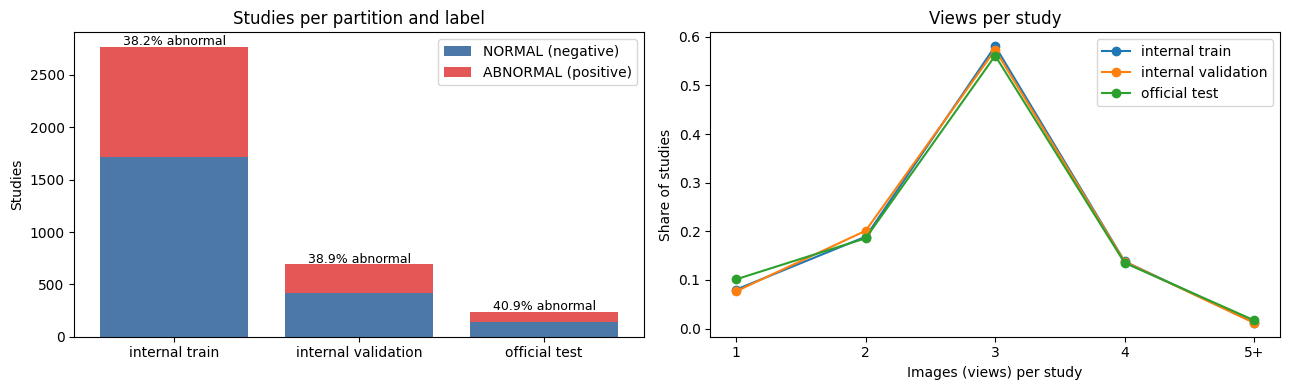

,studies,abnormal_share
views,,
1,275,9.1%
2,662,29.3%
3,2004,43.7%
4+,519,44.7%


,patients
studies per patient,
1,3094
2,157
3,12
4,4


In [15]:
import matplotlib.pyplot as plt
import numpy as np

partitions_studies = {
    "internal train": internal_train_studies,
    "internal validation": internal_val_studies,
    "official test": wrist_test.drop_duplicates("study_uid"),
}

# 1. Class balance per partition (study level)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = list(partitions_studies)
normal = [int((s["label"] == "negative").sum()) for s in partitions_studies.values()]
abnormal = [int((s["label"] == "positive").sum()) for s in partitions_studies.values()]
axes[0].bar(names, normal, label="NORMAL (negative)", color="#4C78A8")
axes[0].bar(names, abnormal, bottom=normal, label="ABNORMAL (positive)", color="#E45756")
for i, (n, a) in enumerate(zip(normal, abnormal)):
    axes[0].text(i, n + a + 15, f"{a / (n + a):.1%} abnormal", ha="center", fontsize=9)
axes[0].set_ylabel("Studies")
axes[0].set_title("Studies per partition and label")
axes[0].legend(loc="upper right")

# 2. Images per study
for name, studies in partitions_studies.items():
    if "image_count" in studies.columns:
        counts = studies["image_count"]
    else:
        counts = wrist_test.groupby("study_uid")["file_name"].count()
    shares = counts.clip(upper=5).value_counts(normalize=True).sort_index()
    axes[1].plot(shares.index, shares.values, marker="o", label=name)
axes[1].set_xticks([1, 2, 3, 4, 5], labels=["1", "2", "3", "4", "5+"])
axes[1].set_xlabel("Images (views) per study")
axes[1].set_ylabel("Share of studies")
axes[1].set_title("Views per study")
axes[1].legend()
plt.tight_layout()
plt.show()

views_vs_label = (
    pd.concat([internal_train_studies, internal_val_studies])
    .assign(views=lambda f: f["image_count"].clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4+"}))
    .groupby("views")["label"].agg(studies="count", abnormal_share=lambda s: (s == "positive").mean())
)
display(views_vs_label.style.format({"abnormal_share": "{:.1%}"}))

studies_per_patient = study_df.groupby("patient_id")["study_uid"].nunique().value_counts().sort_index()
display(studies_per_patient.rename("patients").to_frame().rename_axis("studies per patient"))

,width,height,aspect
count,300.0,300.0,300.0
mean,361.7,506.1,0.7
std,79.8,25.8,0.2
min,155.0,322.0,0.3
25%,291.0,512.0,0.6
50%,393.5,512.0,0.8
75%,406.0,512.0,0.8
max,512.0,512.0,1.6


,images (sample of 300)
mode,
L,156
RGB,144


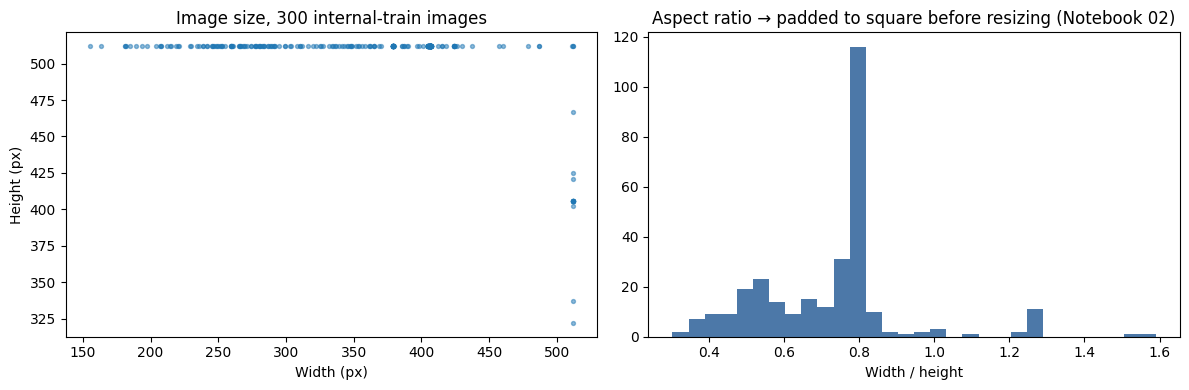

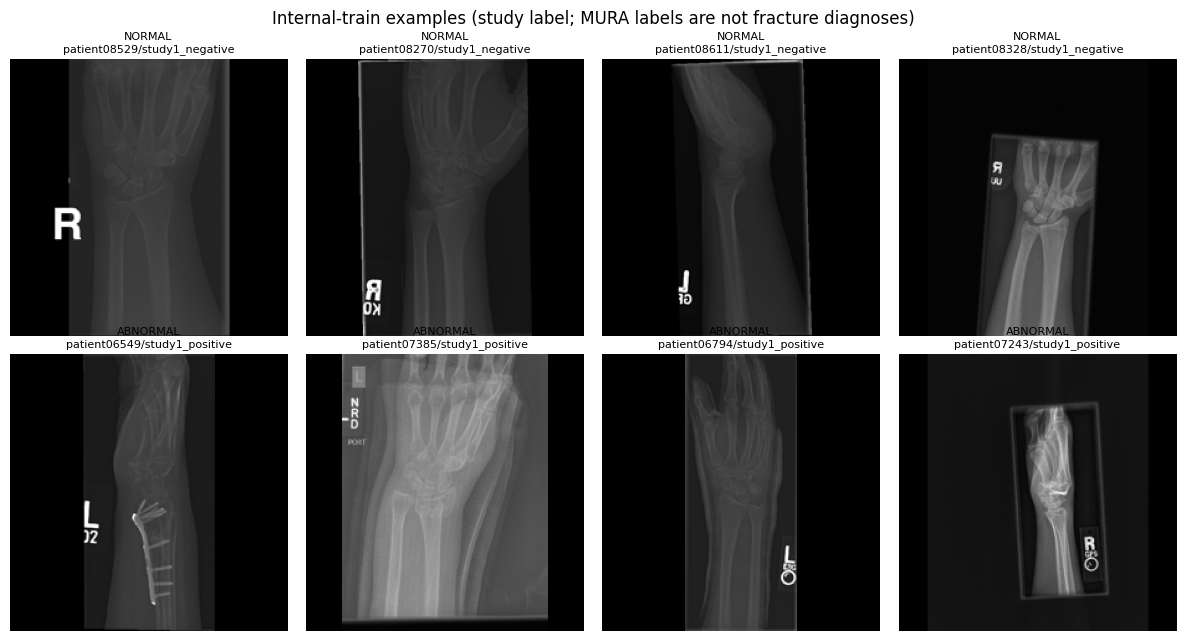

In [16]:
from PIL import Image, ImageOps

rng = np.random.default_rng(RANDOM_STATE)
train_radiographs = wrist_train[
    wrist_train["study_uid"].isin(internal_train_studies["study_uid"])
    & wrist_train["file_name"].str.match(IMAGE_PATTERN)
]
sample = train_radiographs.iloc[rng.choice(len(train_radiographs), size=300, replace=False)]

# 3. Image size and mode (header only, sampled from internal train)
sizes = []
with zipfile.ZipFile(ZIP_PATH) as z:
    for name in sample["file_name"]:
        with z.open(name) as handle:
            image = Image.open(io.BytesIO(handle.read()))
            sizes.append({"width": image.size[0], "height": image.size[1], "mode": image.mode})
sizes = pd.DataFrame(sizes)
sizes["aspect"] = sizes["width"] / sizes["height"]
display(sizes.describe().round(1))
display(sizes["mode"].value_counts().rename("images (sample of 300)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sizes["width"], sizes["height"], s=8, alpha=0.5)
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")
axes[0].set_title("Image size, 300 internal-train images")
axes[1].hist(sizes["aspect"], bins=30, color="#4C78A8")
axes[1].set_xlabel("Width / height")
axes[1].set_title("Aspect ratio → padded to square before resizing (Notebook 02)")
plt.tight_layout()
plt.show()

# 4. Examples: 4 NORMAL and 4 ABNORMAL studies (first image of each), internal train only
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
with zipfile.ZipFile(ZIP_PATH) as z:
    for row_axes, label in zip(axes, ["negative", "positive"]):
        studies = internal_train_studies[internal_train_studies["label"] == label]
        chosen = studies.iloc[rng.choice(len(studies), size=4, replace=False)]["study_uid"]
        for axis, study in zip(row_axes, chosen):
            name = sorted(train_radiographs.loc[train_radiographs["study_uid"] == study, "file_name"])[0]
            with z.open(name) as handle:
                image = ImageOps.pad(Image.open(io.BytesIO(handle.read())).convert("L"), (224, 224), color=0)
            axis.imshow(image, cmap="gray")
            axis.set_title(f"{'ABNORMAL' if label == 'positive' else 'NORMAL'}\n{study}", fontsize=8)
            axis.axis("off")
plt.suptitle("Internal-train examples (study label; MURA labels are not fracture diagnoses)")
plt.tight_layout()
plt.show()

## Export to `DATA/WRIST_SPLITS`

### Step 15 — Image-level manifests (internal train / validation)

In [17]:
internal_train_images = wrist_train[wrist_train["study_uid"].isin(internal_train_studies["study_uid"])]
internal_val_images = wrist_train[wrist_train["study_uid"].isin(internal_val_studies["study_uid"])]

# Radiograph = path matches the MURA image pattern; the 4 macOS '._' files do not.
# They stay in the validation manifest; Notebook 02 removes them (PREPROCESSED_WRIST).
is_radiograph = lambda frame: frame["file_name"].str.match(IMAGE_PATTERN)

run_checks({
    "Train + validation images = 9,756": len(internal_train_images) + len(internal_val_images) == 9_756,
    "Internal train holds only radiographs": is_radiograph(internal_train_images).all(),
    "Validation holds exactly 4 macOS '._' files (Notebook 02 removes them)":
        int((~is_radiograph(internal_val_images)).sum()) == 4,
}, "IMAGE MANIFESTS")
print()

save_or_verify(internal_train_images, OUT_TRAIN_IMAGES)
save_or_verify(internal_val_images, OUT_VAL_IMAGES)

=== IMAGE MANIFESTS ===
✓ PASS: Train + validation images = 9,756
✓ PASS: Internal train holds only radiographs
✓ PASS: Validation holds exactly 4 macOS '._' files (Notebook 02 removes them)

✓ wrist_internal_train.csv: already saved, content verified (7,810 rows).
✓ wrist_internal_val.csv: already saved, content verified (1,946 rows).


### Step 16 — Reload and validate the saved manifests

In [18]:
train = pd.read_csv(OUT_TRAIN_IMAGES)
val = pd.read_csv(OUT_VAL_IMAGES)

for name, data in [("internal train", train), ("internal validation", val)]:
    print(f"{name:28s}: {len(data):5,} images, {data['study_uid'].nunique():,} studies, "
          f"{data['patient_id'].nunique():,} patients")
print()

run_checks({
    "Train + validation images = 9,756": len(train) + len(val) == 9_756,
    "Validation holds exactly 4 macOS '._' files":
        int((~val["file_name"].str.match(IMAGE_PATTERN)).sum()) == 4,
    "No patient overlap": not (set(train["patient_id"]) & set(val["patient_id"])),
    "No study overlap": not (set(train["study_uid"]) & set(val["study_uid"])),
    "Studies match the split record":
        set(train["study_uid"]) | set(val["study_uid"]) == set(split_record["study_uid"]),
}, "SAVED MANIFESTS")

internal train              : 7,810 images, 2,769 studies, 2,614 patients
internal validation         : 1,946 images, 691 studies, 653 patients

=== SAVED MANIFESTS ===
✓ PASS: Train + validation images = 9,756
✓ PASS: Validation holds exactly 4 macOS '._' files
✓ PASS: No patient overlap
✓ PASS: No study overlap
✓ PASS: Studies match the split record


## Official MURA Validation Set = Locked Test Set

The official validation set is our locked final test set: it is not used for training,
model selection or threshold selection.

### Step 17 — Official test set: image manifest

In [19]:
# Saved with the 5 original index columns (format used by the downstream notebooks)
test_images = wrist_test[INDEX_COLUMNS]

run_checks({
    "Official test images = 659": len(test_images) == 659,
    "Official test holds only radiographs": test_images["file_name"].str.match(IMAGE_PATTERN).all(),
}, "OFFICIAL TEST IMAGES")
print()

save_or_verify(test_images, OUT_TEST_IMAGES)

=== OFFICIAL TEST IMAGES ===
✓ PASS: Official test images = 659
✓ PASS: Official test holds only radiographs

✓ wrist_official_validation.csv: already saved, content verified (659 rows).


### Step 18 — Official test set: study labels

In [20]:
# The official file has no header row: <study path>,<label 0/1>
labels = pd.read_csv(VALID_LABELS_CSV, header=None, names=["study_path", "label"])
test_studies = labels[labels["study_path"].str.contains("/valid/XR_WRIST/", regex=False)].copy()

# Cross-check with the labels and studies encoded in the image paths
label_in_path = (
    test_studies["study_path"].str.extract(r"study\d+_(positive|negative)")[0]
    .map({"negative": 0, "positive": 1})
)
study_uid = test_studies["study_path"].str.extract(r"(patient\d+/study\d+_(?:positive|negative))")[0]

print(test_studies["label"].value_counts().rename({0: "normal (0)", 1: "abnormal (1)"}), "\n")

run_checks({
    "Official wrist test studies = 237": len(test_studies) == 237,
    "Label in file = label in path": (label_in_path == test_studies["label"]).all(),
    "Same studies as in the test image manifest": set(study_uid) == set(wrist_test["study_uid"]),
}, "OFFICIAL TEST STUDIES")
print()

save_or_verify(test_studies, OUT_TEST_STUDIES)

label
normal (0)      140
abnormal (1)     97
Name: count, dtype: int64 

=== OFFICIAL TEST STUDIES ===
✓ PASS: Official wrist test studies = 237
✓ PASS: Label in file = label in path
✓ PASS: Same studies as in the test image manifest

✓ wrist_official_validation_studies.csv: already saved, content verified (237 rows).


## Summary of Output Files

```
DATA/
├── MURA-v1.1_files.zip
├── mura_v1_1.csv                      ← file index of the archive
├── train_image_paths.csv / train_labeled_studies.csv
├── valid_image_paths.csv / valid_labeled_studies.csv
├── baseline_features/
└── WRIST_SPLITS/
    ├── mura_wrist_internal_split.csv          study → internal split (source of truth)
    ├── wrist_internal_train.csv               images, internal train
    ├── wrist_internal_val.csv                 images, internal validation
    ├── wrist_official_validation.csv          images, official test set
    └── wrist_official_validation_studies.csv  study labels of the test set (0/1)
```

| File | Content |
|---|---|
| `mura_wrist_internal_split.csv` | 3,460 studies: 2,769 train / 691 validation |
| `wrist_internal_train.csv` | 7,810 images, 2,769 studies |
| `wrist_internal_val.csv` | 1,946 images, 691 studies (incl. 4 macOS `._` files) |
| `wrist_official_validation.csv` | 659 images |
| `wrist_official_validation_studies.csv` | 237 studies: 140 normal / 97 abnormal |

**No longer written here:** `WRIST_SPLITS/wrist_internal_val_clean.csv` (created 10.10.2026, 1,942 images).
No notebook in the repository reads it; the clean validation manifest used downstream is
`PREPROCESSED_WRIST/wrist_internal_val_clean.csv` from Notebook 02. The existing file is left on Drive unchanged.

**Open issues for the team**
- Labels are text (`positive` / `negative`) in the internal manifests but numeric (0 / 1) in
  `wrist_official_validation_studies.csv`.
- One internal-train image (`patient06960/study2_negative/image1.png`) is byte-identical to one
  official-test image (`patient11359/study1_negative/image1.png`) — see Step 14.

**EDA:** tables in Steps 7, 11, 13, 14 and figures in Step 14b (notebook outputs only).